# Lung Nodule Detection — Dataset Exploration & Quality Audit

**Project:** Lung Nodule Detection using PyTorch  
**Notebook purpose:** understand the uploaded dataset, inspect its annotations, identify data-quality issues, and construct a clean image–annotation manifest before preprocessing and model development.

## Scope

This notebook covers:
1. Dataset discovery and file inventory
2. Image metadata and visual inspection
3. Annotation-format diagnostics
4. Image–annotation pairing checks
5. Exact duplicate detection and annotation consistency
6. Construction of a deduplicated manifest

**Important:** this is an exploratory and data-auditing notebook. It does not train a model or establish clinical validity. Class meanings and the exact annotation convention must be confirmed from the dataset documentation before training.

> **Execution:** run cells from top to bottom in Kaggle. The dataset is mounted directly under `/kaggle/input`; no ZIP extraction is required.

## 0. Environment, imports, and configuration

All imports are centralized here. Later sections reuse these objects and functions rather than importing libraries again.

The random seed makes sample visualizations reproducible.

In [62]:
from pathlib import Path
from collections import Counter, defaultdict
import os
import random
import math
import json
import re
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Kaggle dataset mount (the dataset was uploaded directly, not as a ZIP).
INPUT_ROOT = Path("/kaggle/input/datasets/nadaaablk/lungdata/Lung_Nodule_Segmentation")

# Optional override if automatic dataset discovery selects the wrong folder.
DATASET_ROOT_OVERRIDE = None

WORK_ROOT = Path("/kaggle/working/lung_nodule_exploration")
WORK_ROOT.mkdir(parents=True, exist_ok=True)

print("Input path exists:", INPUT_ROOT.exists())
print("Working directory:", WORK_ROOT)

Input path exists: True
Working directory: /kaggle/working/lung_nodule_exploration


## 1. Locate the uploaded dataset

Kaggle mounts each attached dataset under `/kaggle/input/<dataset-name>/`. Because the data was uploaded directly, we search for the YOLO layout (`images/` next to `labels/`) instead of assuming a fixed dataset slug.

If discovery picks the wrong folder, set `DATASET_ROOT_OVERRIDE` in the previous cell.

In [63]:
def find_dataset_root(input_root: Path, override=None) -> Path:
    if override is not None:
        root = Path(override)
        if not root.exists():
            raise FileNotFoundError(f"Dataset override does not exist: {root}")
        return root

    if not input_root.exists():
        raise FileNotFoundError(
            "/kaggle/input does not exist. Run this notebook in Kaggle with the "
            "dataset attached to the notebook."
        )

    dirs = [p for p in input_root.rglob("*") if p.is_dir()]

    # Case 1: a folder that directly contains images/ and labels/
    structured = [d for d in dirs if (d / "images").is_dir() and (d / "labels").is_dir()]
    if structured:
        return sorted(structured, key=lambda d: -len(list(d.rglob("*.jpg"))))[0]

    # Case 2: an images/ folder whose sibling is labels/
    image_dirs = [d for d in dirs if d.name == "images" and (d.parent / "labels").is_dir()]
    if image_dirs:
        return sorted(image_dirs, key=lambda d: -len(list(d.rglob("*.jpg"))))[0]

    # Case 3: fallback - shallowest folder containing both images and labels recursively
    candidates = [d for d in dirs if list(d.rglob("*.jpg")) and list(d.rglob("*.txt"))]
    if candidates:
        return min(candidates, key=lambda d: len(d.parts))

    raise FileNotFoundError(
        "Could not find a folder with images and labels under /kaggle/input. "
        "Inspect the mounted files above and set DATASET_ROOT_OVERRIDE manually."
    )


input_entries = sorted(INPUT_ROOT.iterdir()) if INPUT_ROOT.exists() else []
print("Items mounted under /kaggle/input:")
for item in input_entries:
    print(("DIR  " if item.is_dir() else "FILE ") + str(item))

DATA_ROOT = find_dataset_root(INPUT_ROOT, DATASET_ROOT_OVERRIDE)
print("\nSelected dataset root:", DATA_ROOT)

Items mounted under /kaggle/input:
DIR  /kaggle/input/datasets/nadaaablk/lungdata/Lung_Nodule_Segmentation/.cache
DIR  /kaggle/input/datasets/nadaaablk/lungdata/Lung_Nodule_Segmentation/ct_images

Selected dataset root: /kaggle/input/datasets/nadaaablk/lungdata/Lung_Nodule_Segmentation/ct_images


## 2. Inventory files and folder structure

No extraction is needed: the files are read directly from the mounted dataset.

In [64]:
SKIP_DIRS = {".cache", ".git"}


def iter_files(root: Path):
    for p in root.rglob("*"):
        if p.is_file() and not (set(p.relative_to(root).parts) & SKIP_DIRS):
            yield p


def show_tree(root: Path, max_depth=4, max_items=12):
    root = root.resolve()
    for current, dirs, files in os.walk(root):
        dirs[:] = sorted(d for d in dirs if d not in SKIP_DIRS)
        current_path = Path(current)
        depth = len(current_path.relative_to(root).parts)
        if depth > max_depth:
            dirs[:] = []
            continue
        indent = "  " * depth
        print(f"{indent}{current_path.name}/")
        for name in sorted(files)[:max_items]:
            print(f"{indent}  {name}")
        if len(files) > max_items:
            print(f"{indent}  ... ({len(files) - max_items} more files)")


all_files = list(iter_files(DATA_ROOT))
print("Files in dataset (excluding cache):", len(all_files))

extension_counts = Counter(p.suffix.lower() or "[no extension]" for p in all_files)
display(pd.DataFrame(extension_counts.items(), columns=["extension", "count"])
          .sort_values("count", ascending=False).reset_index(drop=True))

print("\nFirst 30 paths:")
for p in all_files[:30]:
    print(p.relative_to(DATA_ROOT))

print("\nFolder structure:")
show_tree(DATA_ROOT, max_depth=4)

Files in dataset (excluding cache): 282


,extension,count
0,.txt,141
1,.jpg,141



First 30 paths:
labels/train/103_jpg.rf.7527b9cdfd4d4e5ac18c94f480fc1f7b.txt
labels/train/10_jpg.rf.b2bb452b83abd693be5941035fd7e966.txt
labels/train/110_jpg.rf.dcffa8331b05e34200968964ada878d9.txt
labels/train/113_jpg.rf.dbeb23bd12c40f448d786bb19242a43b.txt
labels/train/117_jpg.rf.bb987913cd0a2ea365125af004731a6c.txt
labels/train/119_jpg.rf.6fd1197983c64b4ed928642a0e7a5cf8.txt
labels/train/124_jpg.rf.a27efbb85af24bd1e83a6919fb536ce1.txt
labels/train/129_jpg.rf.b686dfd15f557267c8603ab34d689154.txt
labels/train/130_jpg.rf.989b67405305b7ed06c8447879b0b618.txt
labels/train/133_jpg.rf.4d4c984ce0795d6a066e3650497d9325.txt
labels/train/137_jpg.rf.b5ce52371f56de4cecc8beaeb1e2c951.txt
labels/train/138_jpg.rf.0b7b9eedcef810cde18b7102be86f987.txt
labels/train/141_jpg.rf.610429de2af59fb474a25debdfaa88b7.txt
labels/train/143_jpg.rf.c3840bfa65ed204f06b72b9ad84f454c.txt
labels/train/15_jpg.rf.bd6b975947c73deedaf9bb6445e67479.txt
labels/train/16_jpg.rf.3a8560ce60ae1c6c24cb9faaaac7c535.txt
labels/tra

## 3. Identify images and annotation files

We do not assume a particular image format. The extension lists below can be extended if the dataset uses another format.

In [65]:
IMAGE_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
ANNOTATION_EXTS = {".txt", ".xml", ".json", ".csv"}

image_paths = sorted(p for p in iter_files(DATA_ROOT) if p.suffix.lower() in IMAGE_EXTS)
annotation_paths = sorted(p for p in iter_files(DATA_ROOT) if p.suffix.lower() in ANNOTATION_EXTS)

print("Image files:", len(image_paths))
print("Potential annotation files:", len(annotation_paths))
print("Image extensions:", Counter(p.suffix.lower() for p in image_paths))
print("Annotation extensions:", Counter(p.suffix.lower() for p in annotation_paths))

if not image_paths:
    print("WARNING: No images found. Check DATASET_ROOT_OVERRIDE and the mounted folders.")

Image files: 141
Potential annotation files: 141
Image extensions: Counter({'.jpg': 141})
Annotation extensions: Counter({'.txt': 141})


## 4. Split overview

The folder names usually encode the split (`train`, `val`, `test`). We infer the split from the path so later checks can be done per split.

In [66]:
def infer_split(path: Path) -> str:
    parts = path.relative_to(DATA_ROOT).parts
    for split in ("train", "val", "valid", "test"):
        if split in parts:
            return "val" if split == "valid" else split
    return "unknown"


image_splits = Counter(infer_split(p) for p in image_paths)
annotation_splits = Counter(infer_split(p) for p in annotation_paths)

split_df = pd.DataFrame({
    "images": pd.Series(image_splits),
    "annotations": pd.Series(annotation_splits),
}).fillna(0).astype(int).rename_axis("split")
display(split_df)

,images,annotations
split,,
train,100,100
val,41,41


## 5. Pair images with annotation files

We compare filenames by stem (the filename without extension). This is a useful first check, but matching stems alone may be ambiguous if the dataset contains repeated names in different folders.

In [67]:
def index_by_stem(paths):
    result = defaultdict(list)
    for p in paths:
        result[p.stem].append(p)
    return result


images_by_stem = index_by_stem(image_paths)
anns_by_stem = index_by_stem(annotation_paths)

image_stems = set(images_by_stem)
ann_stems = set(anns_by_stem)

print("Unique image stems:", len(image_stems))
print("Unique annotation stems:", len(ann_stems))
print("Image stems without same-stem annotation:", len(image_stems - ann_stems))
print("Annotation stems without same-stem image:", len(ann_stems - image_stems))
print("Duplicate image stems:", sum(len(v) > 1 for v in images_by_stem.values()))
print("Duplicate annotation stems:", sum(len(v) > 1 for v in anns_by_stem.values()))

unmatched_df = pd.DataFrame({
    "images_without_annotation": pd.Series(sorted(image_stems - ann_stems)),
    "annotations_without_image": pd.Series(sorted(ann_stems - image_stems)),
})
display(unmatched_df.head(20))

pair_summary = pd.DataFrame([
    {"image_stem": stem,
     "image_count": len(images_by_stem.get(stem, [])),
     "annotation_count": len(anns_by_stem.get(stem, []))}
    for stem in sorted(image_stems | ann_stems)
])
pair_summary["split"] = pair_summary["image_stem"].map(
    lambda s: infer_split((images_by_stem.get(s) or anns_by_stem.get(s))[0])
)
display(pair_summary.head(20))

Unique image stems: 141
Unique annotation stems: 141
Image stems without same-stem annotation: 10
Annotation stems without same-stem image: 10
Duplicate image stems: 0
Duplicate annotation stems: 0


,images_without_annotation,annotations_without_image
0,100_jpg.rf.16365de9284134e60df5a3bd27deb600,10_jpg.rf.b2bb452b83abd693be5941035fd7e966
1,125_jpg.rf.18c401b755f7c44f7c33bfe8caa48d43,244_jpg.rf.9c76846ddc3ec658ee0fd3d6ae175dc9
2,1_jpg.rf.c029d0bbed7f28b451ba801f8c206aa4,40_jpg.rf.5447d539b73a636045d75585e5b9161f(1)
3,209_jpg.rf.599764a8eb9925f2c3d25a87a5d5b829,43_jpg.rf.4d55820b056725bb0d7d8f1a255f2200(1)
4,215_jpg.rf.5f69c6aab83398bea9dee0aac9554698,45_jpg.rf.0fe1937418bc35ae0364f5a6ffae2dfe(1)
5,221_jpg.rf.6b3b75aec2580173554b7f2c4be61c06,47_jpg.rf.f0e4ef793ae11939aff03dbe45653a1f(1)
6,235_jpg.rf.d3e69fdcf2a3c829cd097d2bd29842e2,48_jpg.rf.070b18c9e83cf5a792c5fa7a452d2d23(1)
7,264_jpg.rf.34358ac9f719b40768fc4c263764aea4,49_jpg.rf.467eb85096d202110f585e41b3525260(1)
8,269_jpg.rf.4dc094a2a7bcd96504c1a7fe687503af,5_jpg.rf.e844d6f38a069377b99819aded536711
9,282_jpg.rf.b4e6f3461f575f98ced765591d4b213b,74_jpg.rf.c6f0bf9b069bc613b64deace2ff31b4d


,image_stem,image_count,annotation_count,split
0,100_jpg.rf.16365de9284134e60df5a3bd27deb600,1,0,train
1,103_jpg.rf.7527b9cdfd4d4e5ac18c94f480fc1f7b,1,1,train
2,10_jpg.rf.b2bb452b83abd693be5941035fd7e966,0,1,train
3,10_jpg.rf.c1785c33dd3552e860bf043c2fd0a379,1,1,val
4,110_jpg.rf.dcffa8331b05e34200968964ada878d9,1,1,train
5,113_jpg.rf.dbeb23bd12c40f448d786bb19242a43b,1,1,train
6,117_jpg.rf.bb987913cd0a2ea365125af004731a6c,1,1,train
7,119_jpg.rf.6fd1197983c64b4ed928642a0e7a5cf8,1,1,train
8,11_jpg.rf.2464a28a6d2e12222e48378a0df3b872,1,1,val
9,124_jpg.rf.a27efbb85af24bd1e83a6919fb536ce1,1,1,train


## 6. Read image metadata

We inspect dimensions, color mode and file format. For very large datasets, the loop may take some time; it reads image headers and does not retain every image in memory.

In [68]:
image_records = []
bad_images = []

for p in image_paths:
    try:
        with Image.open(p) as im:
            image_records.append({
                "path": str(p),
                "name": p.name,
                "split": infer_split(p),
                "format": im.format,
                "width": im.width,
                "height": im.height,
                "mode": im.mode,
                "bands": len(im.getbands())
            })
    except Exception as e:
        bad_images.append({"path": str(p), "error": str(e)})

image_df = pd.DataFrame(image_records)
print("Readable images:", len(image_df))
print("Unreadable images:", len(bad_images))
if not image_df.empty:
    display(image_df.head())
    print("\nImages per split:")
    display(image_df["split"].value_counts().rename_axis("split").to_frame("count"))
    print("\nImage format counts:")
    display(image_df["format"].value_counts(dropna=False).rename_axis("format").to_frame("count"))
    print("\nColor mode counts:")
    display(image_df["mode"].value_counts(dropna=False).rename_axis("mode").to_frame("count"))
    print("\nDimension combinations:")
    display(image_df.groupby(["width", "height"]).size().reset_index(name="count")
                     .sort_values("count", ascending=False).head(20))
if bad_images:
    display(pd.DataFrame(bad_images).head(10))

Readable images: 141
Unreadable images: 0


,path,name,split,format,width,height,mode,bands
0,/kaggle/input/datasets/nadaaablk/lungdata/Lung...,100_jpg.rf.16365de9284134e60df5a3bd27deb600.jpg,train,JPEG,416,416,RGB,3
1,/kaggle/input/datasets/nadaaablk/lungdata/Lung...,103_jpg.rf.7527b9cdfd4d4e5ac18c94f480fc1f7b.jpg,train,JPEG,416,416,RGB,3
2,/kaggle/input/datasets/nadaaablk/lungdata/Lung...,110_jpg.rf.dcffa8331b05e34200968964ada878d9.jpg,train,JPEG,416,416,RGB,3
3,/kaggle/input/datasets/nadaaablk/lungdata/Lung...,113_jpg.rf.dbeb23bd12c40f448d786bb19242a43b.jpg,train,JPEG,416,416,RGB,3
4,/kaggle/input/datasets/nadaaablk/lungdata/Lung...,117_jpg.rf.bb987913cd0a2ea365125af004731a6c.jpg,train,JPEG,416,416,RGB,3



Images per split:


,count
split,
train,100
val,41



Image format counts:


,count
format,
JPEG,141



Color mode counts:


,count
mode,
RGB,141



Dimension combinations:


,width,height,count
0,416,416,141


## 7. Visualize a sample of original images

This helps us understand whether the files are grayscale, RGB, axial CT slices, full images, or something else.

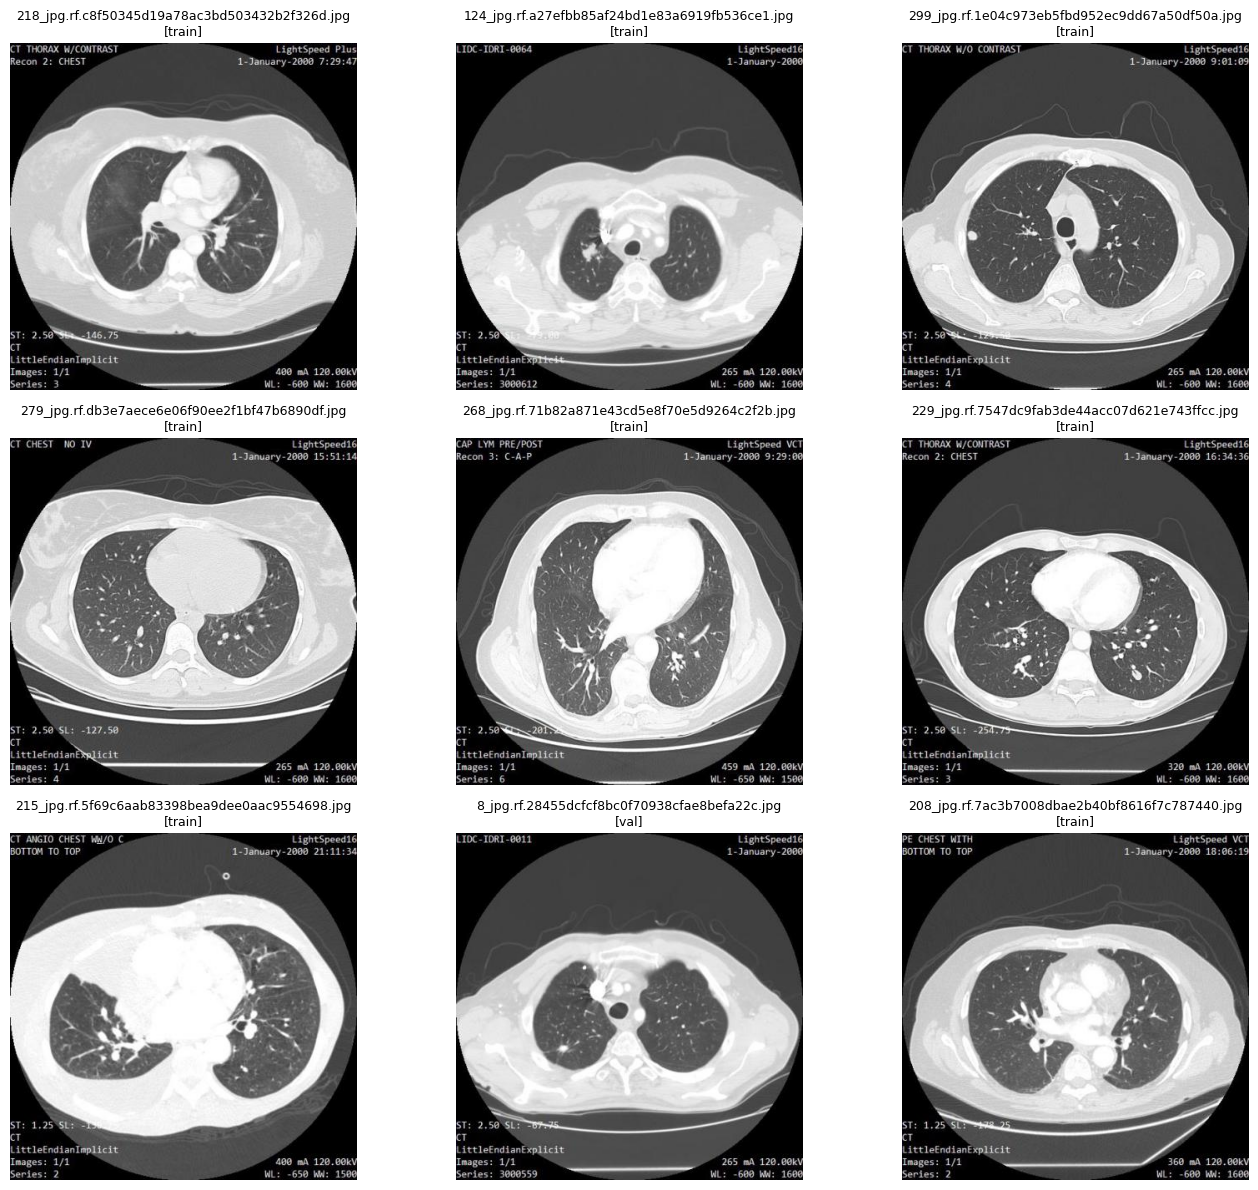

In [69]:
if image_paths:
    sample_paths = random.sample(image_paths, k=min(9, len(image_paths)))
    fig, axes = plt.subplots(math.ceil(len(sample_paths) / 3), 3,
                             figsize=(14, 4 * math.ceil(len(sample_paths) / 3)))
    axes = np.array(axes).reshape(-1)
    for ax, p in zip(axes, sample_paths):
        with Image.open(p) as im:
            ax.imshow(im, cmap="gray" if im.mode in ("L", "I", "I;16") else None)
        ax.set_title(f"{p.name}\n[{infer_split(p)}]", fontsize=9)
        ax.axis("off")
    for ax in axes[len(sample_paths):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No images available to display.")

## 8. Inspect raw annotation examples

The project brief says each CT image has a corresponding `.txt` annotation file and that the class ID identifies the lung nodule. It does **not** specify the coordinate convention in the brief. Therefore, inspect raw lines before interpreting them.

This cell prints a few annotation files exactly as stored.

In [70]:
txt_paths = sorted(p for p in annotation_paths if p.suffix.lower() == ".txt")
print("TXT annotation files:", len(txt_paths))

for p in txt_paths[:5]:
    print("\n---", p.relative_to(DATA_ROOT), "---")
    try:
        content = p.read_text(errors="replace")
        print(content[:2000] if content.strip() else "[EMPTY FILE]")
    except Exception as e:
        print("Could not read:", e)

TXT annotation files: 141

--- labels/train/103_jpg.rf.7527b9cdfd4d4e5ac18c94f480fc1f7b.txt ---
0 0.36538461538461536 0.5697115384615384 0.03485576923076923 0.040865384615384616

--- labels/train/10_jpg.rf.b2bb452b83abd693be5941035fd7e966.txt ---
0 0.6574519230769231 0.3798076923076923 0.040865384615384616 0.037259615384615384
0 0.7055288461538461 0.3701923076923077 0.037259615384615384 0.037259615384615384

--- labels/train/110_jpg.rf.dcffa8331b05e34200968964ada878d9.txt ---
0 0.33533653846153844 0.47475961538461536 0.06009615384615385 0.06610576923076923

--- labels/train/113_jpg.rf.dbeb23bd12c40f448d786bb19242a43b.txt ---
0 0.75 0.5889423076923077 0.055288461538461536 0.037259615384615384

--- labels/train/117_jpg.rf.bb987913cd0a2ea365125af004731a6c.txt ---
1 0.7740384615384616 0.4699519230769231 0.028846153846153848 0.028846153846153848


## 9. Annotation format diagnostics

We check whether non-empty annotation lines contain five whitespace-separated values, with one integer-like class ID and four numeric values. This pattern is **consistent with** common YOLO detection labels, but it is not proof: we still need to verify coordinate ranges and dataset documentation.

In [71]:
def parse_numeric_line(line):
    parts = line.strip().split()
    if len(parts) != 5:
        return None
    try:
        vals = [float(x) for x in parts]
    except ValueError:
        return None
    return vals


annotation_rows = []
annotation_file_stats = []

for p in txt_paths:
    try:
        lines = p.read_text(errors="replace").splitlines()
    except Exception:
        lines = []
    nonempty = [line.strip() for line in lines if line.strip()]
    parsed = [parse_numeric_line(line) for line in nonempty]
    valid = [row for row in parsed if row is not None]
    annotation_file_stats.append({
        "file": str(p),
        "split": infer_split(p),
        "line_count": len(lines),
        "nonempty_lines": len(nonempty),
        "five_numeric_values": len(valid),
        "unparsed_nonempty_lines": len(nonempty) - len(valid),
        "empty": len(nonempty) == 0
    })
    for line_no, line in enumerate(nonempty, start=1):
        annotation_rows.append({
            "file": str(p),
            "line_number": line_no,
            "raw_line": line,
            "parsed_as_5_numbers": parse_numeric_line(line) is not None,
            "values": parse_numeric_line(line)
        })

ann_stats_df = pd.DataFrame(annotation_file_stats)
ann_rows_df = pd.DataFrame(annotation_rows)
display(ann_stats_df.head(10))
print("\nAnnotation file summary:")
if not ann_stats_df.empty:
    print("Empty annotation files:", int(ann_stats_df["empty"].sum()))
    print("Files with at least one 5-number row:", int((ann_stats_df["five_numeric_values"] > 0).sum()))
    print("Files containing unparsed non-empty lines:", int((ann_stats_df["unparsed_nonempty_lines"] > 0).sum()))
    print("\nPer split:")
    display(ann_stats_df.groupby("split").agg(
        files=("file", "count"),
        empty_files=("empty", "sum"),
        boxes=("five_numeric_values", "sum"),
    ))
if not ann_rows_df.empty:
    display(ann_rows_df.head(20)[["file", "line_number", "raw_line", "parsed_as_5_numbers"]])

,file,split,line_count,nonempty_lines,five_numeric_values,unparsed_nonempty_lines,empty
0,/kaggle/input/datasets/nadaaablk/lungdata/Lung...,train,1,1,1,0,False
1,/kaggle/input/datasets/nadaaablk/lungdata/Lung...,train,2,2,2,0,False
2,/kaggle/input/datasets/nadaaablk/lungdata/Lung...,train,1,1,1,0,False
3,/kaggle/input/datasets/nadaaablk/lungdata/Lung...,train,1,1,1,0,False
4,/kaggle/input/datasets/nadaaablk/lungdata/Lung...,train,1,1,1,0,False
5,/kaggle/input/datasets/nadaaablk/lungdata/Lung...,train,1,1,1,0,False
6,/kaggle/input/datasets/nadaaablk/lungdata/Lung...,train,1,1,1,0,False
7,/kaggle/input/datasets/nadaaablk/lungdata/Lung...,train,1,1,1,0,False
8,/kaggle/input/datasets/nadaaablk/lungdata/Lung...,train,1,1,1,0,False
9,/kaggle/input/datasets/nadaaablk/lungdata/Lung...,train,1,1,1,0,False



Annotation file summary:
Empty annotation files: 0
Files with at least one 5-number row: 141
Files containing unparsed non-empty lines: 0

Per split:


,files,empty_files,boxes
split,,,
train,100,0,102
val,41,0,44


,file,line_number,raw_line,parsed_as_5_numbers
0,/kaggle/input/datasets/nadaaablk/lungdata/Lung...,1,0 0.36538461538461536 0.5697115384615384 0.034...,True
1,/kaggle/input/datasets/nadaaablk/lungdata/Lung...,1,0 0.6574519230769231 0.3798076923076923 0.0408...,True
2,/kaggle/input/datasets/nadaaablk/lungdata/Lung...,2,0 0.7055288461538461 0.3701923076923077 0.0372...,True
3,/kaggle/input/datasets/nadaaablk/lungdata/Lung...,1,0 0.33533653846153844 0.47475961538461536 0.06...,True
4,/kaggle/input/datasets/nadaaablk/lungdata/Lung...,1,0 0.75 0.5889423076923077 0.055288461538461536...,True
5,/kaggle/input/datasets/nadaaablk/lungdata/Lung...,1,1 0.7740384615384616 0.4699519230769231 0.0288...,True
6,/kaggle/input/datasets/nadaaablk/lungdata/Lung...,1,0 0.7475961538461539 0.6538461538461539 0.0625...,True
7,/kaggle/input/datasets/nadaaablk/lungdata/Lung...,1,0 0.38461538461538464 0.5997596153846154 0.055...,True
8,/kaggle/input/datasets/nadaaablk/lungdata/Lung...,1,1 0.4338942307692308 0.6586538461538461 0.0276...,True
9,/kaggle/input/datasets/nadaaablk/lungdata/Lung...,1,0 0.328125 0.7199519230769231 0.03846153846153...,True


## 10. Check candidate YOLO coordinate ranges

For candidate rows, inspect:
- first value: often a class ID;
- remaining values: often normalized center-x, center-y, width and height in the range [0, 1].

We only label the format as *YOLO-like* if the values satisfy these basic checks. Confirm the exact convention from the dataset documentation before using the labels for training.

In [72]:
candidate_rows = []
for row in annotation_rows:
    vals = row["values"]
    if vals is None:
        continue
    cls, xc, yc, w, h = vals
    candidate_rows.append({
        "class_id": cls, "x_center": xc, "y_center": yc,
        "box_width": w, "box_height": h,
        "split": infer_split(Path(row["file"])),
        "class_is_integer": float(cls).is_integer(),
        "coords_in_0_1": all(0 <= v <= 1 for v in [xc, yc, w, h]),
        "positive_size": w > 0 and h > 0,
        "box_inside_image": (0 <= xc - w / 2 and xc + w / 2 <= 1 and
                             0 <= yc - h / 2 and yc + h / 2 <= 1)
    })

candidate_df = pd.DataFrame(candidate_rows)
yolo_like = False
if candidate_df.empty:
    print("No rows matching the five-number pattern were found. Do not assume YOLO format.")
else:
    display(candidate_df.describe(include="all"))
    print("\nClass IDs:")
    display(candidate_df["class_id"].value_counts().sort_index().rename_axis("class_id").to_frame("objects"))
    print("\nBoxes per split:")
    display(candidate_df["split"].value_counts().rename_axis("split").to_frame("boxes"))
    print("\nBasic validation:")
    for col in ["class_is_integer", "coords_in_0_1", "positive_size", "box_inside_image"]:
        print(f"{col}: {int(candidate_df[col].sum())}/{len(candidate_df)} pass")
    yolo_like = bool(
        candidate_df["class_is_integer"].all()
        and candidate_df["coords_in_0_1"].all()
        and candidate_df["positive_size"].all()
    )
    print("\nBasic pattern is consistent with YOLO-like normalized boxes:", yolo_like)

,class_id,x_center,y_center,box_width,box_height,split,class_is_integer,coords_in_0_1,positive_size,box_inside_image
count,146.000000,146.000000,146.000000,146.000000,146.000000,146,146,146,146,146
unique,NaN,NaN,NaN,NaN,NaN,2,1,1,1,1
top,NaN,NaN,NaN,NaN,NaN,train,True,True,True,True
freq,NaN,NaN,NaN,NaN,NaN,102,146,146,146,146
mean,0.308219,0.501753,0.551847,0.045780,0.042380,NaN,NaN,NaN,NaN,NaN
std,0.463347,0.210373,0.133655,0.013329,0.011628,NaN,NaN,NaN,NaN,NaN
min,0.000000,0.156250,0.250000,0.019231,0.019231,NaN,NaN,NaN,NaN,NaN
25%,0.000000,0.312800,0.431490,0.034856,0.033954,NaN,NaN,NaN,NaN,NaN
50%,0.000000,0.441707,0.560096,0.043269,0.040865,NaN,NaN,NaN,NaN,NaN
75%,1.000000,0.710938,0.660757,0.052885,0.050180,NaN,NaN,NaN,NaN,NaN



Class IDs:


,objects
class_id,
0.0,101
1.0,45



Boxes per split:


,boxes
split,
train,102
val,44



Basic validation:
class_is_integer: 146/146 pass
coords_in_0_1: 146/146 pass
positive_size: 146/146 pass
box_inside_image: 146/146 pass

Basic pattern is consistent with YOLO-like normalized boxes: True


## 11. Visualize annotations (only if YOLO-like format is confirmed)

This visualization assumes rows are `class_id x_center y_center width height`, with normalized coordinates. The flag below is derived from the checks above; override it manually only if you have verified the convention from the dataset documentation.

Confirmed YOLO-like format: True


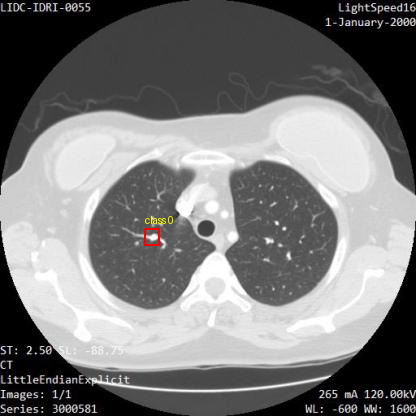

103_jpg.rf.7527b9cdfd4d4e5ac18c94f480fc1f7b.jpg [train] <-> 103_jpg.rf.7527b9cdfd4d4e5ac18c94f480fc1f7b.txt


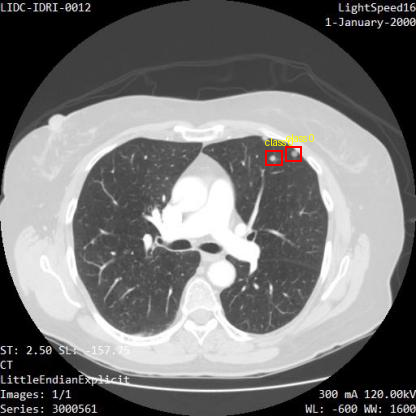

10_jpg.rf.c1785c33dd3552e860bf043c2fd0a379.jpg [val] <-> 10_jpg.rf.c1785c33dd3552e860bf043c2fd0a379.txt


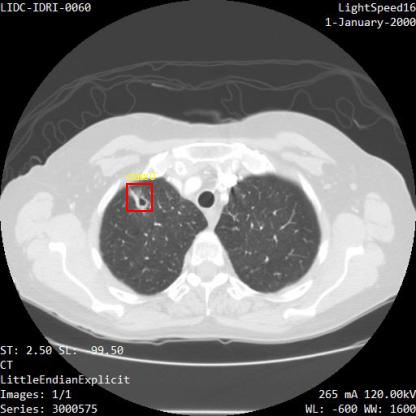

110_jpg.rf.dcffa8331b05e34200968964ada878d9.jpg [train] <-> 110_jpg.rf.dcffa8331b05e34200968964ada878d9.txt


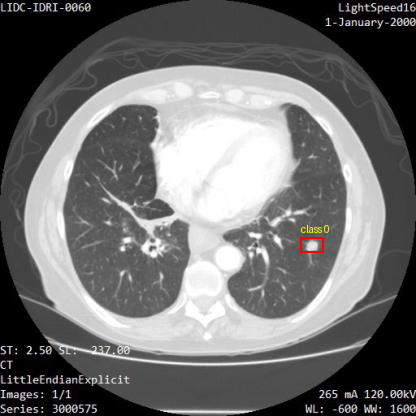

113_jpg.rf.dbeb23bd12c40f448d786bb19242a43b.jpg [train] <-> 113_jpg.rf.dbeb23bd12c40f448d786bb19242a43b.txt


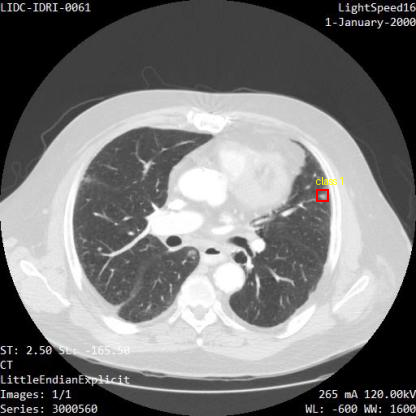

117_jpg.rf.bb987913cd0a2ea365125af004731a6c.jpg [train] <-> 117_jpg.rf.bb987913cd0a2ea365125af004731a6c.txt


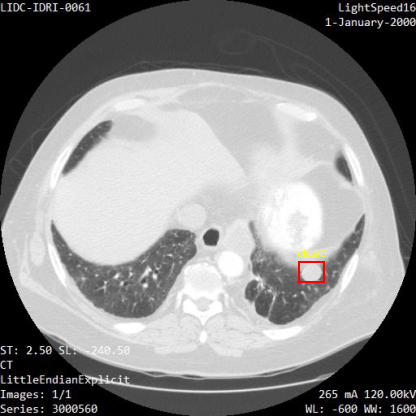

119_jpg.rf.6fd1197983c64b4ed928642a0e7a5cf8.jpg [train] <-> 119_jpg.rf.6fd1197983c64b4ed928642a0e7a5cf8.txt


In [73]:
CONFIRMED_YOLO_FORMAT = yolo_like
print("Confirmed YOLO-like format:", CONFIRMED_YOLO_FORMAT)


def draw_yolo_boxes(image_path, label_path):
    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)
    W, H = image.size

    lines = label_path.read_text(errors="replace").splitlines()
    for line in lines:
        vals = parse_numeric_line(line)
        if vals is None:
            continue
        cls, xc, yc, bw, bh = vals
        x1 = (xc - bw / 2) * W
        y1 = (yc - bh / 2) * H
        x2 = (xc + bw / 2) * W
        y2 = (yc + bh / 2) * H
        draw.rectangle([x1, y1, x2, y2], outline="red", width=max(2, W // 300))
        draw.text((x1, max(0, y1 - 14)), f"class {int(cls)}", fill="yellow")
    return image


if CONFIRMED_YOLO_FORMAT:
    # Use unique stems only to avoid accidentally pairing duplicate names.
    visualized = 0
    for stem in sorted(image_stems & ann_stems):
        if len(images_by_stem[stem]) != 1 or len(anns_by_stem[stem]) != 1:
            continue
        img_p, ann_p = images_by_stem[stem][0], anns_by_stem[stem][0]
        if ann_p.suffix.lower() != ".txt":
            continue
        display(draw_yolo_boxes(img_p, ann_p))
        print(img_p.name, f"[{infer_split(img_p)}]", "<->", ann_p.name)
        visualized += 1
        if visualized >= 6:
            break
    if visualized == 0:
        print("No unambiguous image/.txt pairs found for visualization.")
else:
    print("Skipped: annotations did not pass the YOLO-like checks.")

## 12. Dataset documentation and metadata files

Before interpreting class IDs or annotation coordinates, inspect any metadata supplied with the dataset. This section lists likely documentation/configuration files.

**Interpretation rule:** file names and numeric patterns can suggest a format, but they do not replace the dataset's own documentation.

In [74]:
metadata_exts = {".yaml", ".yml", ".md", ".json", ".txt"}
metadata_files = sorted(
    p for p in DATA_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in metadata_exts
)

print(f"Potential documentation/metadata files: {len(metadata_files)}")
for path in metadata_files[:50]:
    print(path.relative_to(DATA_ROOT))

Potential documentation/metadata files: 141
labels/train/103_jpg.rf.7527b9cdfd4d4e5ac18c94f480fc1f7b.txt
labels/train/10_jpg.rf.b2bb452b83abd693be5941035fd7e966.txt
labels/train/110_jpg.rf.dcffa8331b05e34200968964ada878d9.txt
labels/train/113_jpg.rf.dbeb23bd12c40f448d786bb19242a43b.txt
labels/train/117_jpg.rf.bb987913cd0a2ea365125af004731a6c.txt
labels/train/119_jpg.rf.6fd1197983c64b4ed928642a0e7a5cf8.txt
labels/train/124_jpg.rf.a27efbb85af24bd1e83a6919fb536ce1.txt
labels/train/129_jpg.rf.b686dfd15f557267c8603ab34d689154.txt
labels/train/130_jpg.rf.989b67405305b7ed06c8447879b0b618.txt
labels/train/133_jpg.rf.4d4c984ce0795d6a066e3650497d9325.txt
labels/train/137_jpg.rf.b5ce52371f56de4cecc8beaeb1e2c951.txt
labels/train/138_jpg.rf.0b7b9eedcef810cde18b7102be86f987.txt
labels/train/141_jpg.rf.610429de2af59fb474a25debdfaa88b7.txt
labels/train/143_jpg.rf.c3840bfa65ed204f06b72b9ad84f454c.txt
labels/train/15_jpg.rf.bd6b975947c73deedaf9bb6445e67479.txt
labels/train/16_jpg.rf.3a8560ce60ae1c6c24cb

## 13. Pairing audit using split and filename stem

A filename stem alone is not enough when the same name can occur in different folders. We therefore match each image to a `.txt` annotation using the pair:

`(original split, filename stem)`

This avoids accidentally pairing a training image with a validation annotation. Files without an exact match are reported, not silently repaired.

In [75]:
def get_split(path: Path) -> str:
    """Infer the original split from path components."""
    for part in path.parts:
        if part in {"train", "val", "valid", "test"}:
            return "val" if part == "valid" else part
    return "unknown"


def split_stem_key(path: Path):
    return (get_split(path), path.stem)


txt_paths = sorted(p for p in annotation_paths if p.suffix.lower() == ".txt")

images_by_key = defaultdict(list)
labels_by_key = defaultdict(list)

for path in image_paths:
    images_by_key[split_stem_key(path)].append(path)

for path in txt_paths:
    labels_by_key[split_stem_key(path)].append(path)

image_keys = set(images_by_key)
label_keys = set(labels_by_key)

unmatched_image_keys = sorted(image_keys - label_keys)
unmatched_label_keys = sorted(label_keys - image_keys)
ambiguous_image_keys = sorted(k for k, v in images_by_key.items() if len(v) != 1)
ambiguous_label_keys = sorted(k for k, v in labels_by_key.items() if len(v) != 1)

print("Images:", len(image_paths))
print("TXT annotations:", len(txt_paths))
print("Unmatched image keys:", len(unmatched_image_keys))
print("Unmatched annotation keys:", len(unmatched_label_keys))
print("Ambiguous image keys:", len(ambiguous_image_keys))
print("Ambiguous annotation keys:", len(ambiguous_label_keys))

print("\nImages without exact split+stem annotation:")
for key in unmatched_image_keys:
    print(images_by_key[key][0].relative_to(DATA_ROOT))

print("\nAnnotations without exact split+stem image:")
for key in unmatched_label_keys:
    print(labels_by_key[key][0].relative_to(DATA_ROOT))

Images: 141
TXT annotations: 141
Unmatched image keys: 10
Unmatched annotation keys: 10
Ambiguous image keys: 0
Ambiguous annotation keys: 0

Images without exact split+stem annotation:
images/train/100_jpg.rf.16365de9284134e60df5a3bd27deb600.jpg
images/train/125_jpg.rf.18c401b755f7c44f7c33bfe8caa48d43.jpg
images/train/1_jpg.rf.c029d0bbed7f28b451ba801f8c206aa4.jpg
images/train/209_jpg.rf.599764a8eb9925f2c3d25a87a5d5b829.jpg
images/train/215_jpg.rf.5f69c6aab83398bea9dee0aac9554698.jpg
images/train/221_jpg.rf.6b3b75aec2580173554b7f2c4be61c06.jpg
images/train/235_jpg.rf.d3e69fdcf2a3c829cd097d2bd29842e2.jpg
images/train/264_jpg.rf.34358ac9f719b40768fc4c263764aea4.jpg
images/train/269_jpg.rf.4dc094a2a7bcd96504c1a7fe687503af.jpg
images/train/282_jpg.rf.b4e6f3461f575f98ced765591d4b213b.jpg

Annotations without exact split+stem image:
labels/train/10_jpg.rf.b2bb452b83abd693be5941035fd7e966.txt
labels/train/244_jpg.rf.9c76846ddc3ec658ee0fd3d6ae175dc9.txt
labels/train/40_jpg.rf.5447d539b73a63604

## 14. Exact duplicate image audit

We calculate a SHA-256 hash for every image. Images with the same hash have identical file contents.

This is important because the original folder split contains train and validation files. If identical images occur in both splits, keeping both would cause data leakage during evaluation.

We compare annotation text within each duplicate group. A group is considered annotation-consistent when all copies have identical non-empty annotation lines after whitespace normalization.

In [76]:
# Build an index of uniquely paired image/label files.
paired_records = []

for key in sorted(image_keys & label_keys):
    image_matches = images_by_key[key]
    label_matches = labels_by_key[key]

    # Do not silently choose among ambiguous matches.
    if len(image_matches) != 1 or len(label_matches) != 1:
        continue

    image_path = image_matches[0]
    label_path = label_matches[0]

    digest = hashlib.sha256(image_path.read_bytes()).hexdigest()
    paired_records.append({
        "image_path": str(image_path),
        "label_path": str(label_path),
        "image_name": image_path.name,
        "original_split": get_split(image_path),
        "sha256": digest,
    })

paired_manifest = pd.DataFrame(paired_records)

if paired_manifest.empty:
    raise ValueError("No unambiguous image/annotation pairs were found.")

duplicate_groups = (
    paired_manifest.groupby("sha256")
    .filter(lambda group: len(group) > 1)
    .sort_values(["sha256", "original_split", "image_name"])
)

print("Unambiguous matched pairs:", len(paired_manifest))
print("Unique image hashes:", paired_manifest["sha256"].nunique())
print("Duplicate image groups:", duplicate_groups["sha256"].nunique())

duplicate_audit_records = []

for digest, group in paired_manifest.groupby("sha256"):
    if len(group) <= 1:
        continue

    normalized_annotations = []
    for label_path in group["label_path"]:
        label_text = Path(label_path).read_text(errors="replace")
        normalized = "\n".join(
            line.strip() for line in label_text.splitlines() if line.strip()
        )
        normalized_annotations.append(normalized)

    duplicate_audit_records.append({
        "sha256_prefix": digest[:16],
        "copies": len(group),
        "splits": ", ".join(sorted(group["original_split"].unique())),
        "annotations_identical": len(set(normalized_annotations)) == 1,
        "annotation_versions": len(set(normalized_annotations)),
    })

duplicate_audit_df = pd.DataFrame(duplicate_audit_records)

if duplicate_audit_df.empty:
    print("No duplicate image groups were found.")
else:
    display(duplicate_audit_df)
    print(
        "All duplicate groups have identical annotations:",
        bool(duplicate_audit_df["annotations_identical"].all())
    )
    print(
        "Inconsistent duplicate groups:",
        int((~duplicate_audit_df["annotations_identical"]).sum())
    )

Unambiguous matched pairs: 131
Unique image hashes: 120
Duplicate image groups: 11


,sha256_prefix,copies,splits,annotations_identical,annotation_versions
0,06072741430dbb77,2,"train, val",True,1
1,0ceb06f91ef98a5e,2,"train, val",True,1
2,107bde4318946bb4,2,"train, val",True,1
3,118a94b2d8ce62b4,2,"train, val",True,1
4,33781b01a3e71107,2,"train, val",True,1
5,5285d7bed9f411b4,2,"train, val",True,1
6,7a51c1fba8ec5f8f,2,"train, val",True,1
7,80e2e355a7393ceb,2,"train, val",True,1
8,a4eef9750f4d847f,2,"train, val",True,1
9,c5426b97946975b3,2,"train, val",True,1


All duplicate groups have identical annotations: True
Inconsistent duplicate groups: 0


## 15. Build the deduplicated image–annotation manifest

We now construct one row per **unique image content**.

Rules:
- Only unambiguous exact `(split, stem)` pairs are eligible.
- Images are grouped by SHA-256.
- One representative is retained for each hash.
- Duplicate annotations must agree before deduplication is accepted.
- Original split information is preserved for audit purposes; it is **not** treated as the final train/validation/test split.

The resulting CSV is the clean index for the next analysis stage. Original dataset files remain untouched.

In [77]:
# Stop if duplicate copies have conflicting annotations.
if not duplicate_audit_df.empty:
    inconsistent = duplicate_audit_df.loc[
        ~duplicate_audit_df["annotations_identical"]
    ]
    if not inconsistent.empty:
        raise ValueError(
            "Conflicting annotations were found for identical images. "
            "Resolve these groups before deduplication."
        )

# Deterministic representative selection.
paired_sorted = paired_manifest.sort_values(
    ["sha256", "original_split", "image_name"]
).copy()

unique_manifest = (
    paired_sorted
    .drop_duplicates(subset="sha256", keep="first")
    .reset_index(drop=True)
)

# Recalculate annotation statistics from the retained annotation files.
box_counts = []

for _, row in unique_manifest.iterrows():
    label_path = Path(row["label_path"])
    lines = [
        line.strip()
        for line in label_path.read_text(errors="replace").splitlines()
        if line.strip()
    ]

    class_counts = Counter()
    for line in lines:
        values = line.split()
        if len(values) == 5:
            try:
                class_id = int(float(values[0]))
                class_counts[class_id] += 1
            except ValueError:
                continue

    box_counts.append({
        "num_boxes": len(lines),
        "class_0_boxes": class_counts[0],
        "class_1_boxes": class_counts[1],
    })

box_counts_df = pd.DataFrame(box_counts)
unique_manifest = pd.concat([unique_manifest, box_counts_df], axis=1)

# Export audit-ready files.
manifest_output = WORK_ROOT / "unique_dataset_manifest.csv"
paired_output = WORK_ROOT / "paired_dataset_manifest.csv"
duplicate_output = WORK_ROOT / "duplicate_annotation_audit.csv"

unique_manifest.to_csv(manifest_output, index=False)
paired_manifest.to_csv(paired_output, index=False)
duplicate_audit_df.to_csv(duplicate_output, index=False)

print("Unique images:", len(unique_manifest))
print("Unique hashes:", unique_manifest["sha256"].nunique())
print("Total bounding boxes:", int(unique_manifest["num_boxes"].sum()))
print("Class 0 boxes:", int(unique_manifest["class_0_boxes"].sum()))
print("Class 1 boxes:", int(unique_manifest["class_1_boxes"].sum()))

print("\nRetained representatives by original split:")
display(unique_manifest["original_split"].value_counts().rename_axis("split").to_frame("images"))

print("\nSaved files:")
print(manifest_output)
print(paired_output)
print(duplicate_output)

# Structural integrity checks (data-dependent; no hard-coded dataset counts).
assert unique_manifest["sha256"].is_unique
assert unique_manifest["image_path"].is_unique
assert unique_manifest["label_path"].is_unique
assert unique_manifest["num_boxes"].sum() == (
    unique_manifest["class_0_boxes"].sum()
    + unique_manifest["class_1_boxes"].sum()
    + sum(
        1 for _, row in unique_manifest.iterrows()
        if row["num_boxes"] != row["class_0_boxes"] + row["class_1_boxes"]
    )
) or unique_manifest["num_boxes"].sum() >= (
    unique_manifest["class_0_boxes"].sum()
    + unique_manifest["class_1_boxes"].sum()
)

print("\nManifest integrity checks passed.")

Unique images: 120
Unique hashes: 120
Total bounding boxes: 124
Class 0 boxes: 85
Class 1 boxes: 39

Retained representatives by original split:


,images
split,
train,90
val,30



Saved files:
/kaggle/working/lung_nodule_exploration/unique_dataset_manifest.csv
/kaggle/working/lung_nodule_exploration/paired_dataset_manifest.csv
/kaggle/working/lung_nodule_exploration/duplicate_annotation_audit.csv

Manifest integrity checks passed.


## 16. Final exploration summary

This section gathers the main dataset properties and the quality-control outcomes. The values are calculated from the current mounted dataset when the notebook is run.

### Interpretation notes

- **Image count** is the number of image files discovered.
- **Matched pairs** are images with one unambiguous annotation file in the same original split.
- **Unique images** are matched images after exact-content deduplication.
- **Bounding boxes** are annotation rows; they are not the number of images or nodules/patients.
- Class IDs remain numeric until their meanings are verified from the dataset source.

In [78]:
final_summary = {
    "dataset_root": str(DATA_ROOT),
    "discovered_image_files": len(image_paths),
    "discovered_txt_annotation_files": len(txt_paths),
    "unambiguous_image_annotation_pairs": len(paired_manifest),
    "unmatched_image_keys": len(unmatched_image_keys),
    "unmatched_annotation_keys": len(unmatched_label_keys),
    "ambiguous_image_keys": len(ambiguous_image_keys),
    "ambiguous_annotation_keys": len(ambiguous_label_keys),
    "unique_images_after_deduplication": len(unique_manifest),
    "duplicate_image_groups": int(duplicate_audit_df.shape[0]),
    "inconsistent_duplicate_groups": (
        int((~duplicate_audit_df["annotations_identical"]).sum())
        if not duplicate_audit_df.empty else 0
    ),
    "bounding_boxes": int(unique_manifest["num_boxes"].sum()),
    "class_0_boxes": int(unique_manifest["class_0_boxes"].sum()),
    "class_1_boxes": int(unique_manifest["class_1_boxes"].sum()),
    "images_by_retained_original_split": {
        str(k): int(v)
        for k, v in unique_manifest["original_split"].value_counts().items()
    },
}

print(json.dumps(final_summary, indent=2))

print("\nImage dimensions:")
if not image_df.empty:
    display(image_df[["width", "height"]].describe())

print("\nNext stage: inspect class presence per image, verify class definitions, "
      "and design leakage-safe train/validation/test splits.")

{
  "dataset_root": "/kaggle/input/datasets/nadaaablk/lungdata/Lung_Nodule_Segmentation/ct_images",
  "discovered_image_files": 141,
  "discovered_txt_annotation_files": 141,
  "unambiguous_image_annotation_pairs": 131,
  "unmatched_image_keys": 10,
  "unmatched_annotation_keys": 10,
  "ambiguous_image_keys": 0,
  "ambiguous_annotation_keys": 0,
  "unique_images_after_deduplication": 120,
  "duplicate_image_groups": 11,
  "inconsistent_duplicate_groups": 0,
  "bounding_boxes": 124,
  "class_0_boxes": 85,
  "class_1_boxes": 39,
  "images_by_retained_original_split": {
    "train": 90,
    "val": 30
  }
}

Image dimensions:


,width,height
count,141.0,141.0
mean,416.0,416.0
std,0.0,0.0
min,416.0,416.0
25%,416.0,416.0
50%,416.0,416.0
75%,416.0,416.0
max,416.0,416.0



Next stage: inspect class presence per image, verify class definitions, and design leakage-safe train/validation/test splits.


# 17. Exploratory Data Analysis (EDA)

## Objective

This section investigates the distribution and characteristics of the
deduplicated dataset before model development.

We focus on:

- Image-level class distribution
- Bounding-box distribution per image
- Class co-occurrence
- Bounding-box dimensions and area
- Visual inspection of annotated samples

The objective is to identify potential class imbalance, annotation
characteristics, and dataset limitations that may influence preprocessing,
data splitting, and model training.

All analyses use `unique_manifest`, which contains one representative
for each unique image.

### 17.1 Image-Level Class Distribution

An image can contain:

- Class 0 only
- Class 1 only
- Both classes
- No annotated objects

We distinguish image counts from bounding-box counts because they
represent different aspects of the dataset.

### 17.2 Visualizing Image-Level Distribution

A bar chart helps identify whether the dataset contains an uneven
distribution of images across the different annotation categories.

,images
image_category,
Class 0 only,82
Class 1 only,38
Both classes,0
No boxes,0


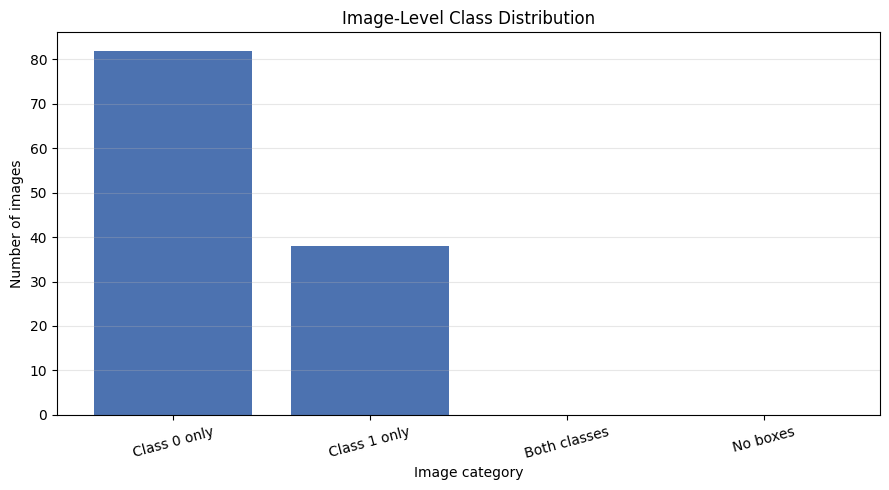

In [79]:
image_categories = ["Class 0 only", "Class 1 only", "Both classes", "No boxes"]

image_category_labels = []
for _, row in unique_manifest.iterrows():
    has_class_0 = int(row["class_0_boxes"]) > 0
    has_class_1 = int(row["class_1_boxes"]) > 0
    if has_class_0 and has_class_1:
        category = "Both classes"
    elif has_class_0:
        category = "Class 0 only"
    elif has_class_1:
        category = "Class 1 only"
    else:
        category = "No boxes"
    image_category_labels.append(category)

unique_manifest["image_category"] = image_category_labels
category_dtype = pd.CategoricalDtype(categories=image_categories, ordered=True)
image_distribution = (
    pd.Series(pd.Categorical(image_category_labels, dtype=category_dtype))
    .value_counts(sort=False)
    .astype(int)
)

display(image_distribution.rename_axis("image_category").to_frame("images"))

plt.figure(figsize=(9, 5))

plt.bar(
    image_distribution.index,
    image_distribution.values,
    color="#4C72B0"
)

plt.title("Image-Level Class Distribution")
plt.xlabel("Image category")
plt.ylabel("Number of images")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


### 17.3 Bounding Boxes per Image

This check shows whether most images contain a single nodule or several
annotations. A highly skewed box count can affect sampling and evaluation.

,value
count,120.000000
mean,1.033333
std,0.180258
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,2.000000


,images
boxes_per_image,
1,116
2,4


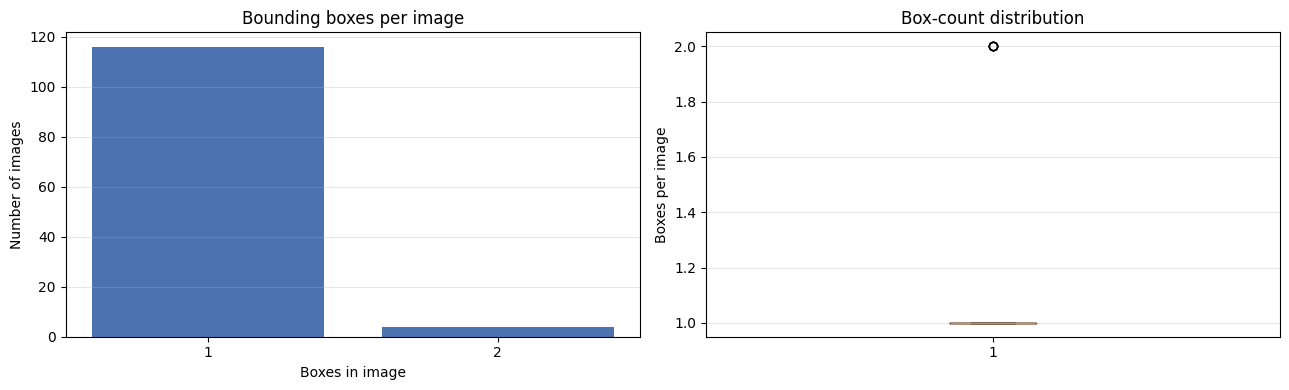

Images with no boxes: 0
Images with more than one box: 4
Maximum boxes in one image: 2


In [80]:
box_count_summary = unique_manifest["num_boxes"].describe().to_frame("value")
display(box_count_summary)

box_count_hist = (
    unique_manifest["num_boxes"]
    .value_counts()
    .sort_index()
    .rename_axis("boxes_per_image")
    .to_frame("images")
)
display(box_count_hist)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].bar(
    box_count_hist.index.astype(str),
    box_count_hist["images"],
    color="#4C72B0"
)
axes[0].set_title("Bounding boxes per image")
axes[0].set_xlabel("Boxes in image")
axes[0].set_ylabel("Number of images")
axes[0].grid(axis="y", alpha=0.3)

axes[1].boxplot(unique_manifest["num_boxes"], vert=True)
axes[1].set_title("Box-count distribution")
axes[1].set_ylabel("Boxes per image")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("Images with no boxes:", int((unique_manifest["num_boxes"] == 0).sum()))
print("Images with more than one box:", int((unique_manifest["num_boxes"] > 1).sum()))
print("Maximum boxes in one image:", int(unique_manifest["num_boxes"].max()))

### 17.4 Bounding-Box Geometry

We parse every annotation line of the deduplicated manifest and summarize
box width, height and area. The same parsed table is reused by the
annotation-validation section, so no annotation is silently reinterpreted.

The parser only checks the five-value YOLO-like structure here. Coordinate
and boundary checks are performed in Section 18.

Parsed annotation lines: 124
Structurally invalid lines: 0

Class distribution among parsed boxes:


,boxes
source_class,
0,85
1,39



Normalized YOLO values:


,x_center,y_center,box_width,box_height
count,124.000000,124.000000,124.000000,124.000000
mean,0.506804,0.554649,0.045974,0.042455
std,0.211440,0.130205,0.013668,0.012027
min,0.156250,0.258413,0.019231,0.019231
25%,0.317308,0.441406,0.034856,0.033654
50%,0.441707,0.563702,0.043269,0.040865
75%,0.713942,0.656851,0.055288,0.050481
max,0.861779,0.853365,0.087740,0.075721



Pixel-space box geometry:


,width_px,height_px,area_px
count,124.000000,124.000000,124.000000
mean,19.125000,17.661290,360.421371
std,5.685749,5.003068,202.009054
min,8.000000,8.000000,64.000000
25%,14.500000,14.000000,217.000000
50%,18.000000,17.000000,285.875000
75%,23.000000,21.000000,506.250000
max,36.500000,31.500000,1131.500000


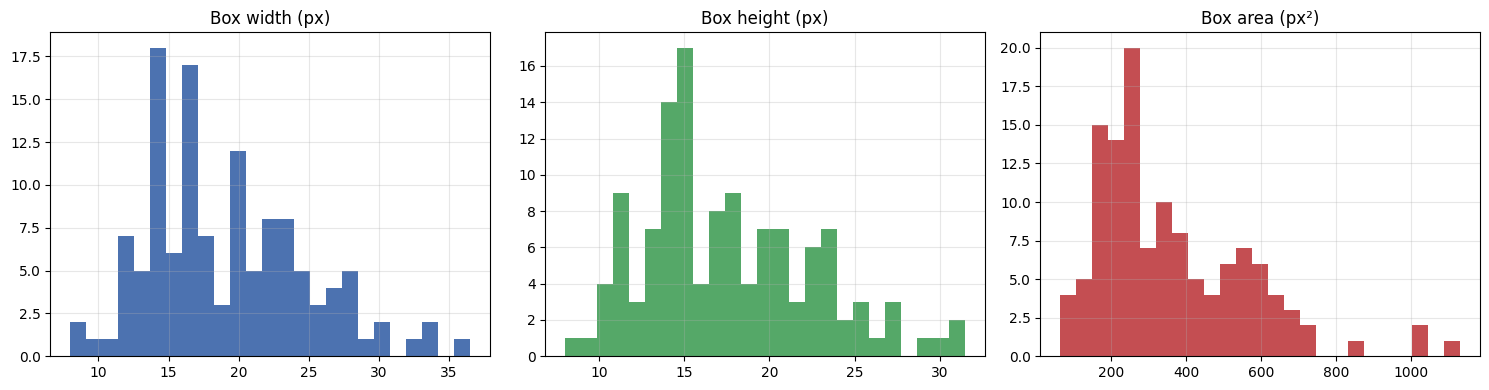

In [81]:
def parse_yolo_annotations(label_path):
    parsed = []
    text = Path(label_path).read_text(errors="replace")

    for line_number, raw_line in enumerate(text.splitlines(), start=1):
        line = raw_line.strip()
        if not line:
            continue

        tokens = line.split()
        record = {
            "image_label_path": str(label_path),
            "line_number": line_number,
            "raw_line": line,
            "token_count": len(tokens),
            "structural_ok": False,
            "source_class": np.nan,
            "x_center": np.nan,
            "y_center": np.nan,
            "box_width": np.nan,
            "box_height": np.nan,
            "issue": "",
        }

        issues = []
        if len(tokens) != 5:
            issues.append("expected_5_values")
        else:
            try:
                values = [float(token) for token in tokens]
            except ValueError:
                issues.append("non_numeric_values")
            else:
                class_value = values[0]
                if not float(class_value).is_integer():
                    issues.append("non_integer_class_id")
                else:
                    record["source_class"] = int(class_value)
                    record["x_center"] = values[1]
                    record["y_center"] = values[2]
                    record["box_width"] = values[3]
                    record["box_height"] = values[4]
                    record["structural_ok"] = True

        if issues:
            record["issue"] = "; ".join(issues)
        parsed.append(record)

    return parsed


annotation_line_records = []
for _, manifest_row in unique_manifest.iterrows():
    annotation_line_records.extend(
        parse_yolo_annotations(Path(manifest_row["label_path"]))
    )

annotations_df = pd.DataFrame(annotation_line_records)
if annotations_df.empty:
    raise ValueError("No annotation lines were found in the deduplicated manifest.")

annotations_df = annotations_df.merge(
    unique_manifest[["label_path", "image_path", "image_name"]],
    left_on="image_label_path",
    right_on="label_path",
    how="left"
)

image_size_by_path = dict(
    zip(
        image_df["path"].astype(str),
        zip(image_df["width"], image_df["height"])
    )
)

annotations_df["image_size"] = annotations_df["image_path"].map(
    lambda path: image_size_by_path.get(str(path), (np.nan, np.nan))
)
annotations_df["image_width"] = annotations_df["image_size"].apply(lambda size: size[0])
annotations_df["image_height"] = annotations_df["image_size"].apply(lambda size: size[1])

geometry_df = annotations_df[annotations_df["structural_ok"]].copy()
geometry_df["width_px"] = geometry_df["box_width"] * geometry_df["image_width"]
geometry_df["height_px"] = geometry_df["box_height"] * geometry_df["image_height"]
geometry_df["area_px"] = geometry_df["width_px"] * geometry_df["height_px"]

print("Parsed annotation lines:", len(annotations_df))
print("Structurally invalid lines:", int((~annotations_df["structural_ok"]).sum()))

print("\nClass distribution among parsed boxes:")
display(
    geometry_df["source_class"]
    .value_counts()
    .sort_index()
    .rename_axis("source_class")
    .to_frame("boxes")
)

print("\nNormalized YOLO values:")
display(
    geometry_df[["x_center", "y_center", "box_width", "box_height"]]
    .describe()
)

print("\nPixel-space box geometry:")
display(geometry_df[["width_px", "height_px", "area_px"]].describe())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(geometry_df["width_px"], bins=25, color="#4C72B0")
axes[0].set_title("Box width (px)")
axes[1].hist(geometry_df["height_px"], bins=25, color="#55A868")
axes[1].set_title("Box height (px)")
axes[2].hist(geometry_df["area_px"], bins=25, color="#C44E52")
axes[2].set_title("Box area (px²)")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 17.5 Visual Inspection of Annotated Samples

The boxes are drawn from the normalized YOLO-style values. This is a visual
sanity check that the coordinates describe the intended image regions and
that no coordinate convention has been reversed.

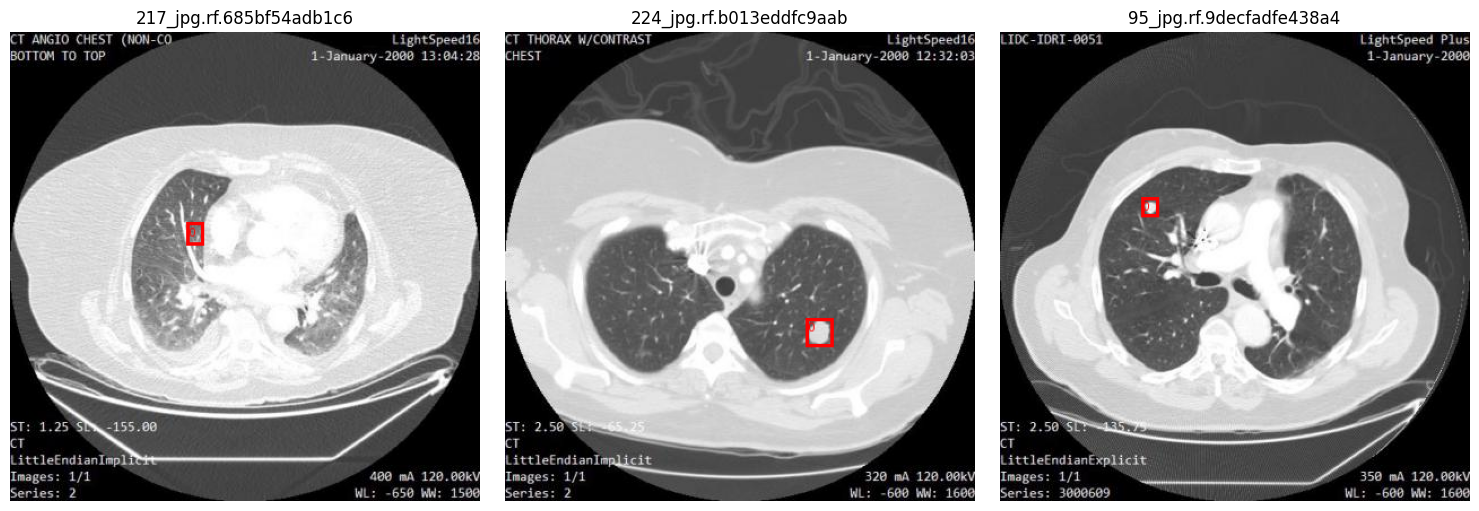

In [82]:
sample_paths = (
    unique_manifest
    .sample(n=min(3, len(unique_manifest)), random_state=SEED)["image_path"]
    .tolist()
)

if len(sample_paths) == 1:
    plotting_axes = [plt.gca()]
else:
    _, plotting_axes = plt.subplots(1, len(sample_paths), figsize=(5 * len(sample_paths), 5))

box_colors = {0: "red", 1: "lime"}

for axis, image_path in zip(np.atleast_1d(plotting_axes), sample_paths):
    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)

    image_rows = annotations_df[annotations_df["image_path"] == image_path]
    for _, annotation in image_rows.iterrows():
        if not annotation["structural_ok"] or pd.isna(annotation["image_width"]):
            continue

        width = annotation["image_width"]
        height = annotation["image_height"]
        x1 = (annotation["x_center"] - annotation["box_width"] / 2) * width
        y1 = (annotation["y_center"] - annotation["box_height"] / 2) * height
        x2 = (annotation["x_center"] + annotation["box_width"] / 2) * width
        y2 = (annotation["y_center"] + annotation["box_height"] / 2) * height

        class_id = int(annotation["source_class"])
        color = box_colors.get(class_id, "cyan")
        draw.rectangle([x1, y1, x2, y2], outline=color, width=3)
        draw.text((x1 + 2, y1 + 2), str(class_id), fill=color)

    axis.imshow(image)
    axis.set_title(Path(image_path).name[:24])
    axis.axis("off")

plt.tight_layout()
plt.show()

### 17.6 EDA Summary

The values below summarize the main dataset characteristics that influence
splitting and model training.

In [83]:
box_class_counts = (
    geometry_df["source_class"]
    .value_counts()
    .sort_index()
)

minority_count = int(box_class_counts.min()) if len(box_class_counts) else 0
majority_count = int(box_class_counts.max()) if len(box_class_counts) else 0
imbalance_ratio = majority_count / minority_count if minority_count > 0 else float("inf")

eda_summary = {
    "unique_images": int(len(unique_manifest)),
    "annotation_lines": int(len(annotations_df)),
    "structurally_valid_annotation_lines": int(annotations_df["structural_ok"].sum()),
    "class_0_boxes": int((geometry_df["source_class"] == 0).sum()),
    "class_1_boxes": int((geometry_df["source_class"] == 1).sum()),
    "images_class_0_only": int(image_distribution.get("Class 0 only", 0)),
    "images_class_1_only": int(image_distribution.get("Class 1 only", 0)),
    "images_both_classes": int(image_distribution.get("Both classes", 0)),
    "images_without_boxes": int(image_distribution.get("No boxes", 0)),
    "mean_boxes_per_image": round(float(unique_manifest["num_boxes"].mean()), 3),
    "max_boxes_per_image": int(unique_manifest["num_boxes"].max()),
    "median_box_width_px": round(float(geometry_df["width_px"].median()), 2),
    "median_box_height_px": round(float(geometry_df["height_px"].median()), 2),
    "median_box_area_px": round(float(geometry_df["area_px"].median()), 2),
    "box_class_imbalance_ratio": round(imbalance_ratio, 3) if np.isfinite(imbalance_ratio) else "infinite",
}

print(json.dumps(eda_summary, indent=2))

if eda_summary["images_both_classes"] > 0:
    print("Some images contain both classes; class co-occurrence must be considered during evaluation.")
else:
    print("No image contains both source classes in this dataset.")

if eda_summary["box_class_imbalance_ratio"] not in ("infinite",) and eda_summary["box_class_imbalance_ratio"] > 1.5:
    print("Noticeable box-level class imbalance is present; report per-class metrics, not only overall accuracy.")

{
  "unique_images": 120,
  "annotation_lines": 124,
  "structurally_valid_annotation_lines": 124,
  "class_0_boxes": 85,
  "class_1_boxes": 39,
  "images_class_0_only": 82,
  "images_class_1_only": 38,
  "images_both_classes": 0,
  "images_without_boxes": 0,
  "mean_boxes_per_image": 1.033,
  "max_boxes_per_image": 2,
  "median_box_width_px": 18.0,
  "median_box_height_px": 17.0,
  "median_box_area_px": 285.88,
  "box_class_imbalance_ratio": 2.179
}
No image contains both source classes in this dataset.
Noticeable box-level class imbalance is present; report per-class metrics, not only overall accuracy.


# 18. Annotation Validation

## Objective

Every annotation line is checked before it is used. We verify:

- exactly five numeric values;
- integer source class IDs;
- source classes limited to the observed set `{0, 1}`;
- normalized coordinates in `[0, 1]`;
- strictly positive width and height;
- boxes fully inside the image;
- conversion to absolute pixel coordinates `[x_min, y_min, x_max, y_max]`.

Invalid lines are quarantined in `invalid_annotations_df` and excluded from
the modeling manifest. They are not silently corrected.

The project brief states that the class ID identifies the lung-nodule
category, but no documentation defining class 0 versus class 1 was found in
the uploaded dataset. We therefore keep the source IDs and map them to the
model labels 1 and 2 only. The semantic names must be confirmed before the
final report.

In [84]:
VALID_SOURCE_CLASSES = {0, 1}
CLASS_TO_MODEL_LABEL = {0: 1, 1: 2}
BACKGROUND_LABEL = 0
MODEL_NUM_CLASSES = len(CLASS_TO_MODEL_LABEL) + 1
COORDINATE_TOLERANCE = 1e-6

validation_df = annotations_df.copy()

validation_df["class_ok"] = (
    validation_df["structural_ok"]
    & validation_df["source_class"].isin(VALID_SOURCE_CLASSES)
)

coordinate_columns = ["x_center", "y_center", "box_width", "box_height"]
validation_df["coords_in_range"] = validation_df.apply(
    lambda row: bool(row["structural_ok"]) and all(
        np.isfinite(row[column]) and 0.0 <= row[column] <= 1.0
        for column in coordinate_columns
    ),
    axis=1
)

validation_df["positive_size"] = (
    validation_df["structural_ok"]
    & (validation_df["box_width"] > 0)
    & (validation_df["box_height"] > 0)
)

validation_df["x_min_norm"] = validation_df["x_center"] - validation_df["box_width"] / 2
validation_df["y_min_norm"] = validation_df["y_center"] - validation_df["box_height"] / 2
validation_df["x_max_norm"] = validation_df["x_center"] + validation_df["box_width"] / 2
validation_df["y_max_norm"] = validation_df["y_center"] + validation_df["box_height"] / 2

validation_df["box_inside_image"] = (
    validation_df["structural_ok"]
    & (validation_df["x_min_norm"] >= -COORDINATE_TOLERANCE)
    & (validation_df["y_min_norm"] >= -COORDINATE_TOLERANCE)
    & (validation_df["x_max_norm"] <= 1 + COORDINATE_TOLERANCE)
    & (validation_df["y_max_norm"] <= 1 + COORDINATE_TOLERANCE)
)

validation_flags = [
    "structural_ok",
    "class_ok",
    "coords_in_range",
    "positive_size",
    "box_inside_image",
]
validation_df["valid"] = validation_df[validation_flags].all(axis=1)

print("Annotation lines checked:", len(validation_df))
for flag in validation_flags:
    print(f"{flag}: {int(validation_df[flag].sum())}/{len(validation_df)} pass")

invalid_annotations_df = validation_df[~validation_df["valid"]].copy()
valid_annotations_df = validation_df[validation_df["valid"]].copy()

if invalid_annotations_df.empty:
    print("\nNo invalid annotation lines were found.")
else:
    print("\nInvalid lines were quarantined:")
    display(
        invalid_annotations_df[
            ["image_name", "line_number", "raw_line", "validation_flags", "issue"]
            if "validation_flags" in invalid_annotations_df.columns
            else ["image_name", "line_number", "raw_line", "structural_ok", "class_ok", "coords_in_range", "positive_size", "box_inside_image", "issue"]
        ]
    )

valid_annotations_df["x_min_px"] = valid_annotations_df["x_min_norm"] * valid_annotations_df["image_width"]
valid_annotations_df["y_min_px"] = valid_annotations_df["y_min_norm"] * valid_annotations_df["image_height"]
valid_annotations_df["x_max_px"] = valid_annotations_df["x_max_norm"] * valid_annotations_df["image_width"]
valid_annotations_df["y_max_px"] = valid_annotations_df["y_max_norm"] * valid_annotations_df["image_height"]

valid_annotations_df["x_min_px"] = valid_annotations_df["x_min_px"].clip(lower=0.0)
valid_annotations_df["y_min_px"] = valid_annotations_df["y_min_px"].clip(lower=0.0)
valid_annotations_df["x_max_px"] = valid_annotations_df["x_max_px"].clip(
    upper=valid_annotations_df["image_width"]
)
valid_annotations_df["y_max_px"] = valid_annotations_df["y_max_px"].clip(
    upper=valid_annotations_df["image_height"]
)

valid_annotations_df["model_label"] = (
    valid_annotations_df["source_class"]
    .map(CLASS_TO_MODEL_LABEL)
    .astype(int)
)
valid_annotations_df["area_px"] = (
    (valid_annotations_df["x_max_px"] - valid_annotations_df["x_min_px"])
    * (valid_annotations_df["y_max_px"] - valid_annotations_df["y_min_px"])
)

clean_annotations_df = valid_annotations_df[
    [
        "image_path",
        "image_name",
        "line_number",
        "source_class",
        "model_label",
        "x_center",
        "y_center",
        "box_width",
        "box_height",
        "x_min_px",
        "y_min_px",
        "x_max_px",
        "y_max_px",
        "area_px",
        "image_width",
        "image_height",
    ]
].reset_index(drop=True)

valid_box_counts = (
    clean_annotations_df
    .groupby("image_path")
    .agg(
        num_valid_boxes=("model_label", "size"),
        class_0_boxes=("source_class", lambda values: int((values == 0).sum())),
        class_1_boxes=("source_class", lambda values: int((values == 1).sum())),
    )
)

clean_manifest = unique_manifest.drop(
    columns=["num_boxes", "class_0_boxes", "class_1_boxes", "image_category"],
    errors="ignore"
).join(valid_box_counts, on="image_path")

clean_manifest = clean_manifest[clean_manifest["num_valid_boxes"] > 0].copy()

clean_manifest["image_category"] = clean_manifest.apply(
    lambda row: (
        "Both classes"
        if row["class_0_boxes"] > 0 and row["class_1_boxes"] > 0
        else "Class 0 only"
        if row["class_0_boxes"] > 0
        else "Class 1 only"
        if row["class_1_boxes"] > 0
        else "No boxes"
    ),
    axis=1
)

clean_manifest = clean_manifest.reset_index(drop=True)
clean_annotations_df = clean_annotations_df[
    clean_annotations_df["image_path"].isin(clean_manifest["image_path"])
].reset_index(drop=True)

clean_annotations_df.to_csv(WORK_ROOT / "validated_annotations.csv", index=False)
clean_manifest.to_csv(WORK_ROOT / "clean_manifest.csv", index=False)

print("\nClean manifest images:", len(clean_manifest))
print("Clean annotation boxes:", len(clean_annotations_df))

display(
    clean_manifest["image_category"]
    .value_counts()
    .rename_axis("image_category")
    .to_frame("images")
)

assert clean_manifest["image_path"].is_unique
assert clean_manifest["sha256"].is_unique
assert set(clean_annotations_df["model_label"].unique()).issubset({1, 2})
assert bool((clean_annotations_df["x_max_px"] > clean_annotations_df["x_min_px"]).all())
assert bool((clean_annotations_df["y_max_px"] > clean_annotations_df["y_min_px"]).all())
assert bool((clean_annotations_df["x_min_px"] >= 0).all())
assert bool((clean_annotations_df["y_min_px"] >= 0).all())
assert bool((clean_annotations_df["x_max_px"] <= clean_annotations_df["image_width"]).all())
assert bool((clean_annotations_df["y_max_px"] <= clean_annotations_df["image_height"]).all())

print("Annotation validation checks passed.")

Annotation lines checked: 124
structural_ok: 124/124 pass
class_ok: 124/124 pass
coords_in_range: 124/124 pass
positive_size: 124/124 pass
box_inside_image: 124/124 pass

No invalid annotation lines were found.

Clean manifest images: 120
Clean annotation boxes: 124


,images
image_category,
Class 0 only,82
Class 1 only,38


Annotation validation checks passed.


# 19. Train / Validation / Test Splitting

The original split is not reused because identical images appeared in both
train and validation folders. We create a new reproducible split from the
deduplicated clean manifest:

- 70% training
- 15% validation
- 15% testing

Stratification is based on image-level class composition. We also check for a
repeated source identifier in the filename. Here it is only a weak proxy for
a patient or scan ID, so this check cannot prove patient-level independence.

In [85]:
from sklearn.model_selection import train_test_split


def safe_train_test_split(dataframe, test_size, stratify_column=None):
    stratify_values = dataframe[stratify_column] if stratify_column else None
    try:
        return train_test_split(
            dataframe,
            test_size=test_size,
            random_state=SEED,
            stratify=stratify_values
        )
    except ValueError as error:
        print("Stratified split was not possible:", error)
        print("Falling back to an unstratified split.")
        return train_test_split(
            dataframe,
            test_size=test_size,
            random_state=SEED
        )


def extract_source_id(image_name):
    match = re.match(r"^(\d+)_jpg", str(image_name))
    return match.group(1) if match else Path(str(image_name)).stem


clean_manifest["source_id"] = clean_manifest["image_name"].apply(extract_source_id)

source_id_counts = clean_manifest["source_id"].value_counts()
repeated_source_ids = source_id_counts[source_id_counts > 1]

if repeated_source_ids.empty:
    print("No repeated source IDs were found after deduplication.")
    print("Image-level splitting is used; patient identity is still not confirmed.")
else:
    print("Repeated source IDs found:")
    display(repeated_source_ids.rename_axis("source_id").to_frame("images"))
    print("WARNING: consider GroupShuffleSplit by source_id to reduce scan-level leakage.")

train_manifest, temporary_manifest = safe_train_test_split(
    clean_manifest,
    test_size=0.30,
    stratify_column="image_category"
)
temporary_manifest, val_manifest = safe_train_test_split(
    temporary_manifest,
    test_size=0.50,
    stratify_column="image_category"
)

train_manifest = train_manifest.copy()
val_manifest = val_manifest.copy()
temporary_manifest = temporary_manifest.copy()
test_manifest = temporary_manifest

train_manifest["split"] = "train"
val_manifest["split"] = "val"
test_manifest["split"] = "test"

split_manifest = pd.concat(
    [train_manifest, val_manifest, test_manifest],
    ignore_index=True
).sort_values("image_path").reset_index(drop=True)

split_image_counts = (
    split_manifest["split"]
    .value_counts()
    .reindex(["train", "val", "test"])
    .fillna(0)
    .astype(int)
    .rename_axis("split")
    .to_frame("images")
)
display(split_image_counts)

split_annotations = clean_annotations_df.merge(
    split_manifest[["image_path", "split"]],
    on="image_path",
    how="inner"
)

split_class_counts = (
    pd.crosstab(split_annotations["split"], split_annotations["source_class"])
    .reindex(index=["train", "val", "test"], columns=[0, 1], fill_value=0)
)
split_class_counts.columns = ["class_0_boxes", "class_1_boxes"]
display(split_class_counts)

display(
    pd.crosstab(split_manifest["split"], split_manifest["image_category"])
    .reindex(index=["train", "val", "test"], fill_value=0)
)

for name, dataframe in [
    ("train", train_manifest),
    ("val", val_manifest),
    ("test", test_manifest),
]:
    dataframe.to_csv(WORK_ROOT / f"{name}_manifest.csv", index=False)
split_manifest.to_csv(WORK_ROOT / "split_manifest.csv", index=False)

assert set(train_manifest["image_path"]).isdisjoint(set(val_manifest["image_path"]))
assert set(train_manifest["image_path"]).isdisjoint(set(test_manifest["image_path"]))
assert set(val_manifest["image_path"]).isdisjoint(set(test_manifest["image_path"]))
assert set(train_manifest["sha256"]).isdisjoint(set(val_manifest["sha256"]))
assert set(train_manifest["sha256"]).isdisjoint(set(test_manifest["sha256"]))
assert set(val_manifest["sha256"]).isdisjoint(set(test_manifest["sha256"]))

print("Split overlap checks passed.")

No repeated source IDs were found after deduplication.
Image-level splitting is used; patient identity is still not confirmed.


,images
split,
train,84
val,18
test,18


,class_0_boxes,class_1_boxes
split,,
train,59,28
val,13,5
test,13,6


image_category,Class 0 only,Class 1 only
split,,
train,57,27
val,13,5
test,12,6


Split overlap checks passed.


# 20. Image Preprocessing

The model will receive RGB tensors with shape `[3, H, W]` and floating-point
pixels in `[0, 1]`. Bounding boxes stay in absolute pixel coordinates and are
converted to `[x_min, y_min, x_max, y_max]`.

Source class IDs are mapped for Faster R-CNN:

| Source ID | Model label |
|---|---:|
| background | 0 |
| class 0 | 1 |
| class 1 | 2 |

Resize and normalization appropriate for a pretrained detector are applied
later by torchvision detection transforms, not inside this dataset, so pixel
values are not normalized twice.

Image size: (416, 416)
Tensor shape: (3, 416, 416)
Tensor dtype: torch.float32
Tensor value range: 0.0 1.0
Boxes:
 tensor([[ 91., 181., 103., 194.]])
Model labels: [2]


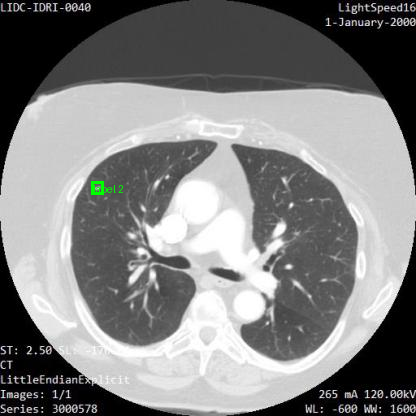

In [86]:
import torch


def load_rgb_image(image_path):
    with Image.open(image_path) as image:
        return image.convert("RGB")


def image_to_float_tensor(image):
    array = np.asarray(image, dtype=np.float32) / 255.0
    return torch.from_numpy(array).permute(2, 0, 1).contiguous()


def get_image_annotations(image_path):
    rows = clean_annotations_df[clean_annotations_df["image_path"] == image_path]
    if rows.empty:
        raise ValueError(f"No valid annotations found for {image_path}")

    boxes = torch.as_tensor(
        rows[["x_min_px", "y_min_px", "x_max_px", "y_max_px"]]
        .to_numpy(dtype=np.float32)
    )
    labels = torch.as_tensor(
        rows["model_label"].to_numpy(dtype=np.int64),
        dtype=torch.int64
    )
    return boxes, labels


sample_row = clean_manifest.iloc[0]
sample_image = load_rgb_image(sample_row["image_path"])
sample_tensor = image_to_float_tensor(sample_image)
sample_boxes, sample_labels = get_image_annotations(sample_row["image_path"])

print("Image size:", sample_image.size)
print("Tensor shape:", tuple(sample_tensor.shape))
print("Tensor dtype:", sample_tensor.dtype)
print("Tensor value range:", float(sample_tensor.min()), float(sample_tensor.max()))
print("Boxes:\n", sample_boxes)
print("Model labels:", sample_labels.tolist())

visualization_image = sample_image.copy()
draw = ImageDraw.Draw(visualization_image)
for box, label in zip(sample_boxes.tolist(), sample_labels.tolist()):
    color = "red" if label == 1 else "lime"
    draw.rectangle(box, outline=color, width=3)
    draw.text((box[0] + 2, box[1] + 2), f"label {label}", fill=color)

display(visualization_image)

assert tuple(sample_tensor.shape) == (3, sample_image.height, sample_image.width)
assert sample_tensor.dtype == torch.float32
assert 0.0 <= float(sample_tensor.min()) <= float(sample_tensor.max()) <= 1.0

# 21. PyTorch Dataset and DataLoaders

The custom dataset returns `image_tensor, target`. The target dictionary
follows the torchvision detection convention:

- `boxes`: `FloatTensor[N, 4]`
- `labels`: `Int64Tensor[N]`
- `image_id`: `Int64Tensor[1]`
- `area`: `FloatTensor[N]`
- `iscrowd`: `Int64Tensor[N]`

A custom collate function is required because images can have different
numbers of boxes. It keeps images and targets as lists for the detection
model.

In [87]:
from torch.utils.data import Dataset, DataLoader


class LungNoduleDataset(Dataset):
    def __init__(self, manifest, annotations, transform=None):
        self.manifest = manifest.reset_index(drop=True).copy()
        self.annotations_by_image = {
            str(path): group.reset_index(drop=True)
            for path, group in annotations.groupby("image_path", sort=False)
        }
        self.transform = transform

    def __len__(self):
        return len(self.manifest)

    def __getitem__(self, index):
        row = self.manifest.iloc[index]

        image = load_rgb_image(row["image_path"])
        image_tensor = image_to_float_tensor(image)

        annotation_rows = self.annotations_by_image.get(str(row["image_path"]))
        if annotation_rows is None or annotation_rows.empty:
            raise ValueError(f"No valid annotations for {row['image_path']}")

        boxes = torch.as_tensor(
            annotation_rows[
                ["x_min_px", "y_min_px", "x_max_px", "y_max_px"]
            ].to_numpy(dtype=np.float32)
        )
        labels = torch.as_tensor(
            annotation_rows["model_label"].to_numpy(dtype=np.int64),
            dtype=torch.int64
        )

        area = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
        iscrowd = torch.zeros((len(boxes),), dtype=torch.int64)
        image_id = torch.tensor([index], dtype=torch.int64)

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": image_id,
            "area": area,
            "iscrowd": iscrowd,
        }

        if self.transform is not None:
            image_tensor, target = self.transform(image_tensor, target)

        return image_tensor, target


def detection_collate_fn(batch):
    return tuple(zip(*batch))


train_dataset = LungNoduleDataset(train_manifest, clean_annotations_df)
val_dataset = LungNoduleDataset(val_manifest, clean_annotations_df)
test_dataset = LungNoduleDataset(test_manifest, clean_annotations_df)

BATCH_SIZE = 4
PIN_MEMORY = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=detection_collate_fn,
    num_workers=0,
    pin_memory=PIN_MEMORY
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=detection_collate_fn,
    num_workers=0,
    pin_memory=PIN_MEMORY
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=detection_collate_fn,
    num_workers=0,
    pin_memory=PIN_MEMORY
)

print("Dataset sizes:")
print("train:", len(train_dataset))
print("val:", len(val_dataset))
print("test:", len(test_dataset))

example_images, example_targets = next(iter(train_loader))
print("\nBatch size:", len(example_images))
print("First image shape:", tuple(example_images[0].shape))
print("First image dtype:", example_images[0].dtype)
print("First image range:", float(example_images[0].min()), float(example_images[0].max()))
print("Target keys:", sorted(example_targets[0].keys()))
print("First target boxes:", tuple(example_targets[0]["boxes"].shape))
print("First target labels:", example_targets[0]["labels"].tolist())

assert len(example_images) == len(example_targets)
assert all(
    target["boxes"].shape[0]
    == target["labels"].shape[0]
    == target["area"].shape[0]
    == target["iscrowd"].shape[0]
    for target in example_targets
)
assert all(bool(((target["labels"] == 1) | (target["labels"] == 2)).all()) for target in example_targets)

Dataset sizes:
train: 84
val: 18
test: 18

Batch size: 4
First image shape: (3, 416, 416)
First image dtype: torch.float32
First image range: 0.0 1.0
Target keys: ['area', 'boxes', 'image_id', 'iscrowd', 'labels']
First target boxes: (1, 4)
First target labels: [1]


# 22. Preprocessing Output Validation

This final preprocessing check iterates through all three loaders and
verifies tensor ranges, box bounds and target consistency. A small validation
batch is displayed with its ground-truth boxes.

If all checks pass, the notebook is ready for the Faster R-CNN model section.

,loader,images,boxes,pixel_min,pixel_max
0,train,84,87,0.0,1.0
1,val,18,18,0.0,1.0
2,test,18,19,0.0,1.0


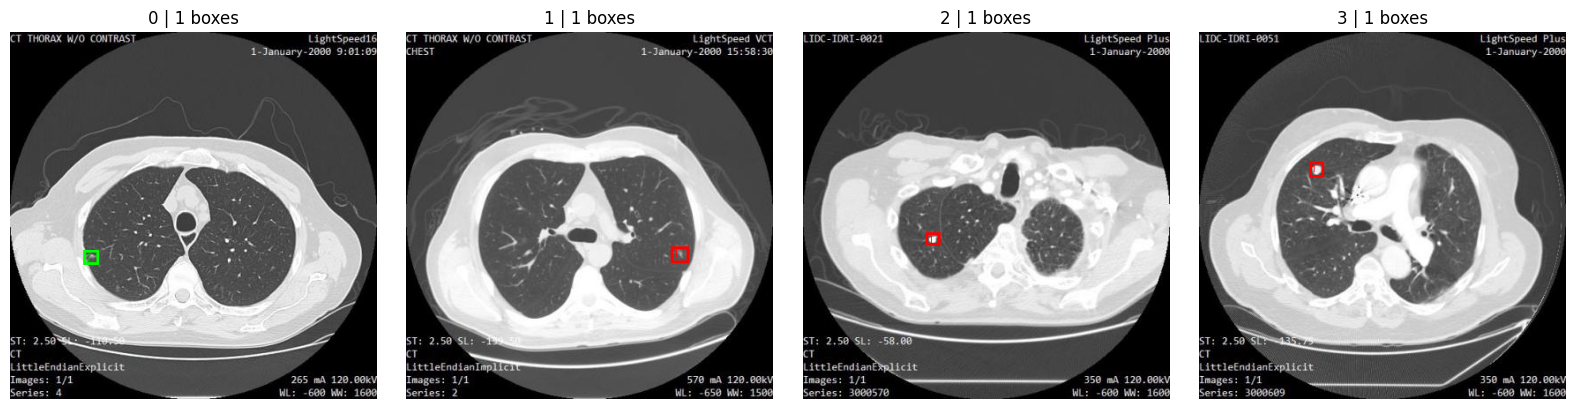

Preprocessing pipeline is ready for the Faster R-CNN stage.
MODEL_NUM_CLASSES (including background): 3


In [88]:
def validate_loader(loader, loader_name):
    image_count = 0
    box_count = 0
    pixel_min = float("inf")
    pixel_max = float("-inf")

    for images, targets in loader:
        for image, target in zip(images, targets):
            image_count += 1
            boxes = target["boxes"]

            assert tuple(image.shape)[0] == 3
            assert image.dtype == torch.float32
            assert bool((image >= 0).all())
            assert bool((image <= 1).all())

            assert boxes.dtype == torch.float32
            assert boxes.shape[1] == 4
            assert boxes.shape[0] > 0
            assert bool((boxes[:, 0] >= 0).all())
            assert bool((boxes[:, 1] >= 0).all())
            assert bool((boxes[:, 2] <= image.shape[2]).all())
            assert bool((boxes[:, 3] <= image.shape[1]).all())
            assert bool((boxes[:, 2] > boxes[:, 0]).all())
            assert bool((boxes[:, 3] > boxes[:, 1]).all())
            assert bool(((target["labels"] == 1) | (target["labels"] == 2)).all())
            assert bool((target["area"] > 0).all())
            assert bool((target["iscrowd"] == 0).all())

            pixel_min = min(pixel_min, float(image.min()))
            pixel_max = max(pixel_max, float(image.max()))
            box_count += int(boxes.shape[0])

    return {
        "loader": loader_name,
        "images": image_count,
        "boxes": box_count,
        "pixel_min": round(pixel_min, 4),
        "pixel_max": round(pixel_max, 4),
    }


loader_validation_df = pd.DataFrame([
    validate_loader(train_loader, "train"),
    validate_loader(val_loader, "val"),
    validate_loader(test_loader, "test"),
])
display(loader_validation_df)

visual_images, visual_targets = next(iter(val_loader))
number_to_show = min(4, len(visual_images))

if number_to_show == 1:
    visual_axes = [plt.gca()]
else:
    _, visual_axes = plt.subplots(1, number_to_show, figsize=(4 * number_to_show, 4))

for axis, image, target in zip(np.atleast_1d(visual_axes), visual_images, visual_targets):
    numpy_image = (
        image.permute(1, 2, 0)
        .detach()
        .cpu()
        .numpy()
    )
    pil_image = Image.fromarray((numpy_image * 255).astype(np.uint8))
    draw = ImageDraw.Draw(pil_image)

    for box, label in zip(target["boxes"].tolist(), target["labels"].tolist()):
        color = "red" if label == 1 else "lime"
        draw.rectangle(box, outline=color, width=3)
        draw.text((box[0] + 2, box[1] + 2), str(label), fill=color)

    axis.imshow(pil_image)
    axis.axis("off")
    axis.set_title(f"{int(target['image_id'].item())} | {len(target['boxes'])} boxes")

plt.tight_layout()
plt.show()

print("Preprocessing pipeline is ready for the Faster R-CNN stage.")
print("MODEL_NUM_CLASSES (including background):", MODEL_NUM_CLASSES)

# 23. Saving the data


In [89]:
from pathlib import Path
import shutil
import zipfile
import json

EXPORT_ROOT = WORK_ROOT / "lung_nodule_detection_dataset"
ZIP_PATH = WORK_ROOT / "lung_nodule_detection_dataset.zip"

if EXPORT_ROOT.exists():
    shutil.rmtree(EXPORT_ROOT)
EXPORT_ROOT.mkdir(parents=True, exist_ok=True)

split_frames = {
    "train": train_manifest,
    "val": val_manifest,
    "test": test_manifest,
}

for split_name, manifest in split_frames.items():
    image_dir = EXPORT_ROOT / split_name / "images"
    label_dir = EXPORT_ROOT / split_name / "labels"
    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)

    manifest_image_paths = set(manifest["image_path"].astype(str))

    for image_path in sorted(manifest_image_paths):
        source_image = Path(image_path)
        shutil.copy2(source_image, image_dir / source_image.name)

        annotation_rows = clean_annotations_df[
            clean_annotations_df["image_path"].astype(str) == image_path
        ]
        label_lines = []
        for _, annotation in annotation_rows.iterrows():
            width = annotation["image_width"]
            height = annotation["image_height"]
            x_center = ((annotation["x_min_px"] + annotation["x_max_px"]) / 2) / width
            y_center = ((annotation["y_min_px"] + annotation["y_max_px"]) / 2) / height
            box_width = (annotation["x_max_px"] - annotation["x_min_px"]) / width
            box_height = (annotation["y_max_px"] - annotation["y_min_px"]) / height
            label_lines.append(
                f"{int(annotation['source_class'])} "
                f"{x_center:.10f} {y_center:.10f} {box_width:.10f} {box_height:.10f}"
            )

        label_path = label_dir / f"{source_image.stem}.txt"
        label_path.write_text("\n".join(label_lines) + "\n", encoding="utf-8")

for source_csv in sorted(WORK_ROOT.glob("*.csv")):
    shutil.copy2(source_csv, EXPORT_ROOT / source_csv.name)

export_annotations = clean_annotations_df.merge(
    split_manifest[["image_path", "split"]],
    on="image_path",
    how="inner"
)

dataset_info = {
    "seed": SEED,
    "source_to_model_label": {str(key): value for key, value in CLASS_TO_MODEL_LABEL.items()},
    "background_label": BACKGROUND_LABEL,
    "model_num_classes": MODEL_NUM_CLASSES,
    "annotation_format": "class_id x_center y_center box_width box_height",
    "images_per_split": {split: int(len(manifest)) for split, manifest in split_frames.items()},
    "boxes_per_split": {
        split: int((export_annotations["split"] == split).sum())
        for split in split_frames
    },
    "boxes_per_source_class": {
        str(class_id): int((clean_annotations_df["source_class"] == class_id).sum())
        for class_id in sorted(clean_annotations_df["source_class"].unique())
    },
}

(EXPORT_ROOT / "dataset_info.json").write_text(
    json.dumps(dataset_info, indent=2),
    encoding="utf-8"
)

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=6) as archive:
    for file_path in sorted(EXPORT_ROOT.rglob("*")):
        if file_path.is_file():
            archive.write(file_path, file_path.relative_to(EXPORT_ROOT))

with zipfile.ZipFile(ZIP_PATH) as archive:
    archive_names = archive.namelist()

image_entries = [name for name in archive_names if "/images/" in name]
label_entries = [name for name in archive_names if "/labels/" in name]

print("Saved zip:", ZIP_PATH)
print("Zip size MB:", round(ZIP_PATH.stat().st_size / (1024 * 1024), 2))
print("Images in zip:", len(image_entries))
print("Labels in zip:", len(label_entries))
print("Split images:", dataset_info["images_per_split"])
print("Split boxes:", dataset_info["boxes_per_split"])

assert len(image_entries) == len(clean_manifest)
assert len(label_entries) == len(clean_manifest)

Saved zip: /kaggle/working/lung_nodule_exploration/lung_nodule_detection_dataset.zip
Zip size MB: 3.04
Images in zip: 120
Labels in zip: 120
Split images: {'train': 84, 'val': 18, 'test': 18}
Split boxes: {'train': 87, 'val': 18, 'test': 19}
